# 36 - Módulo Q: o normal de cada troço, anomalias e tendências

| | |
|---|---|
| **Tarefa do plano** | W3-05 |
| **O que faz** | Calcula o valor normal de cada troço em cada mês do ano, aponta os meses fora do normal e testa se há tendência em 20 anos |
| **Usa** | `data/processed/training/qualidade_trocos.parquet` (notebook 29) |
| **Produz** | Tabelas e figuras em `reports/semana_3/` (prefixo 36) |

| Pergunta | Método |
|---|---|
| Qual é o normal de cada troço em cada mês? | mediana e percentis dos anos com dados |
| Que meses fugiram ao normal? | comparação com o normal; e Isolation Forest para meses invulgares |
| A água está a ficar mais turva ao longo dos anos? | teste de Mann-Kendall sazonal e inclinação de Sen |

Todas as análises usam o **índice de cor (NDTI)**, que é o valor mais repetível.
A turbidez em FNU é só uma tradução aproximada desse índice.

In [1]:
import json
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ete import config, module_q
from ete import module_q_analysis as Q

cfg = config.load_config()
REPORTS = config.path(cfg, "reports", "semana_3")       # figuras e tabelas para o relatório
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_colwidth", 90)

## 1. O normal de cada troço em cada mês do ano

troco,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9
anos_com_dados_min,7,7,8,7,8,8,8,13,12
anos_com_dados_max,10,10,10,10,10,10,18,20,20


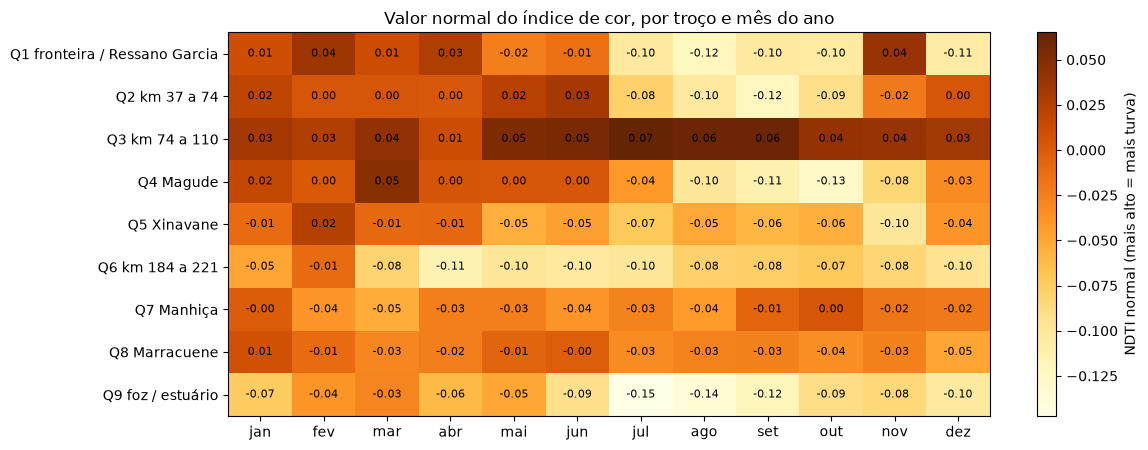

In [2]:
data, skill, _ = Q.expected_turbidity(cfg, Q.monthly_dataset(cfg))
normal = Q.climatology(data, "ndti")
normal.round(4).to_csv(REPORTS / "36_normais_por_troco_e_mes.csv")
grid = normal["mediana"].unstack("mes").reindex(sorted(data["troco"].unique()))
names = data.drop_duplicates("troco").set_index("troco")["nome"]
fig, ax = plt.subplots(figsize=(12, 4.6))
im = ax.imshow(grid.values, cmap="YlOrBr", aspect="auto")
ax.set_xticks(range(12), ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]); ax.set_yticks(range(len(grid)), [names[t] for t in grid.index])
for (i, j), v in np.ndenumerate(grid.values):
    if np.isfinite(v):
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, ax=ax, label="NDTI normal (mais alto = mais turva)"); ax.set_title("Valor normal do índice de cor, por troço e mês do ano")
plt.tight_layout(); plt.savefig(REPORTS / "36_normais.png", dpi=110)
normal.groupby("troco")["anos"].agg(["min", "max"]).rename(columns={"min": "anos_com_dados_min", "max": "anos_com_dados_max"}).T

**Leitura.** Cada linha é um troço, da fronteira (em cima) à foz (em baixo). Lê-se
em duas direções: ao longo do ano (a água é mais turva na época das chuvas) e ao
longo do rio (onde é mais turva).

Os troços estreitos têm menos anos (só Sentinel-2). Um mês do ano com menos de
quatro anos de dados fica sem valor normal.

## 2. Meses fora do normal

Um mês é **elevado** se ficar acima de três quartos dos mesmos meses dos outros
anos, e **muito elevado** se ficar acima de nove décimos.

,nome,month,ndti,mediana,anomalia,anomalia_padronizada
493,Q2 km 37 a 74,2026-04,0.096,0.002,0.094,3.051
213,Q1 fronteira / Ressano Garcia,2023-10,0.129,-0.104,0.233,2.883
891,Q4 Magude,2017-10,0.053,-0.129,0.182,2.880
993,Q4 Magude,2026-04,0.088,0.005,0.083,2.835
1477,Q6 km 184 a 221,2024-12,-0.013,-0.095,0.082,2.393
1499,Q6 km 184 a 221,2026-10,-0.011,-0.073,0.062,2.273
431,Q2 km 37 a 74,2021-02,0.140,0.004,0.136,2.252
450,Q2 km 37 a 74,2022-09,0.039,-0.123,0.162,2.180
2169,Q9 foz / estuário,2020-02,0.118,-0.038,0.156,2.101
900,Q4 Magude,2018-07,0.120,-0.042,0.162,2.009


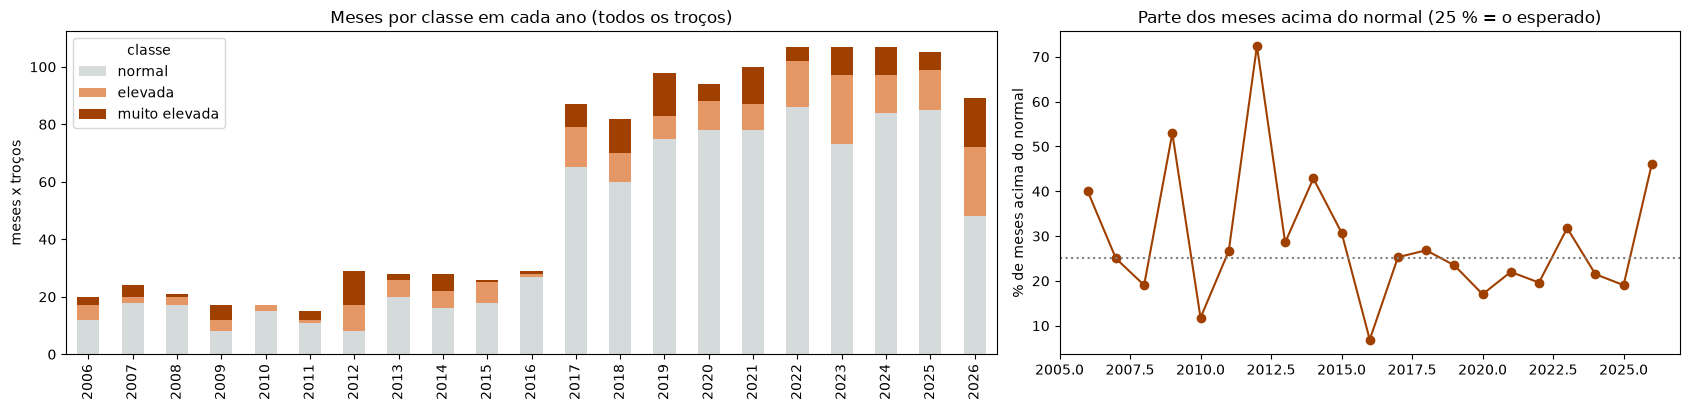

In [3]:
anomaly = Q.anomalies(data, "ndti")
anomaly.round(4).to_csv(REPORTS / "36_anomalias.csv", index=False)
order = ["normal", "elevada", "muito elevada"]
counts = anomaly[anomaly["classe"] != "sem dados"].groupby(["ano", "classe"]).size().unstack(fill_value=0).reindex(columns=order, fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(17, 4.2), gridspec_kw={"width_ratios": [1.5, 1]})
counts.plot.bar(stacked=True, ax=axes[0], color=["#d5dbdb", "#e59866", "#a04000"]); axes[0].set_ylabel("meses x troços"); axes[0].set_xlabel("")
axes[0].set_title("Meses por classe em cada ano (todos os troços)")
share = anomaly[anomaly["classe"] != "sem dados"].assign(alto=lambda d: d["classe"] != "normal").groupby("ano")["alto"].mean()
(100 * share).plot(ax=axes[1], marker="o", color="#a04000"); axes[1].axhline(25, color="grey", linestyle=":"); axes[1].set_ylabel("% de meses acima do normal"); axes[1].set_xlabel("")
axes[1].set_title("Parte dos meses acima do normal (25 % = o esperado)")
plt.tight_layout(); plt.savefig(REPORTS / "36_anomalias_por_ano.png", dpi=110)
worst = anomaly[anomaly["classe"] == "muito elevada"].sort_values("anomalia_padronizada", ascending=False).head(15)
worst[["nome", "month", "ndti", "mediana", "anomalia", "anomalia_padronizada"]]

**Leitura.** O gráfico da direita mostra, ano a ano, que parte dos meses medidos
ficou acima do normal. A tabela mostra os quinze meses mais fora do normal de
todo o registo.

**Cuidado ao comparar anos.** Até 2013 os valores dos troços largos vêm do
Landsat 5 e 7; depois, do Landsat 8 e 9. As bandas não são iguais, e em 2012 só
havia o Landsat 7, com faixas sem dados. Um ano antigo "muito turvo" pode ser em
parte efeito do satélite. As comparações seguras são dentro da mesma era, e é
por isso que a ficha de evidência (notebook 38) só usa os anos desde 2013.

## 3. Meses invulgares (Isolation Forest)

O método anterior olha para uma coisa de cada vez. O Isolation Forest olha para
várias em conjunto (a cor, as plantas sobre a água e, onde existe, o desvio face
ao que a chuva e o caudal explicam) e aponta os 5 % de meses mais invulgares de
cada troço. Um mês apontado é um convite a ir ver, não um diagnóstico.

65 meses apontados em 1230 medidos


,nome,month,anomalia_ndti,anomalia_vegetacao,caudal_m3s,chuva_mm,pontuacao
56,Q9 foz / estuário,2014-06,0.087,18.436,1.534,8.645,-0.779
50,Q8 Marracuene,2016-06,-6.435,-2.235,1.761,11.787,-0.778
19,Q4 Magude,2020-04,-7.669,0.581,36.092,48.720,-0.768
55,Q9 foz / estuário,2013-12,-5.897,0.428,79.487,134.019,-0.764
52,Q8 Marracuene,2018-06,1.239,6.017,1.322,9.679,-0.756
43,Q7 Manhiça,2026-02,-1.047,-4.474,482.184,42.613,-0.753
0,Q1 fronteira / Ressano Garcia,2019-02,-2.541,3.441,98.383,171.862,-0.746
1,Q1 fronteira / Ressano Garcia,2020-02,-2.102,4.128,194.636,120.561,-0.745
59,Q9 foz / estuário,2015-07,-6.841,2.077,0.771,10.450,-0.738
18,Q4 Magude,2017-10,2.880,1.733,10.543,54.579,-0.731


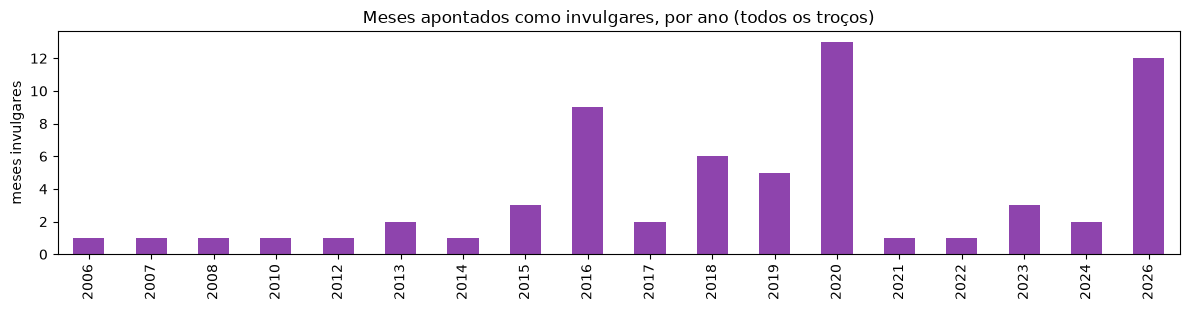

In [4]:
unusual = Q.isolation_forest(cfg, data)
unusual.round(4).to_csv(REPORTS / "36_meses_invulgares.csv", index=False)
flagged = unusual[unusual["invulgar"]].merge(data[["troco", "month", "nome", "caudal_m3s", "chuva_mm"]], on=["troco", "month"])
per_year = flagged.assign(ano=flagged["month"].str[:4]).groupby("ano").size()
ax = per_year.plot.bar(figsize=(12, 3.2), color="#8e44ad", ylabel="meses invulgares"); ax.set_xlabel(""); ax.set_title("Meses apontados como invulgares, por ano (todos os troços)")
plt.tight_layout(); plt.savefig(REPORTS / "36_meses_invulgares.png", dpi=110)
print(f"{len(flagged)} meses apontados em {len(unusual)} medidos")
flagged.sort_values("pontuacao").head(15)[["nome", "month", "anomalia_ndti", "anomalia_vegetacao", "caudal_m3s", "chuva_mm", "pontuacao"]]

## 4. Tendências em 20 anos

O teste de Mann-Kendall sazonal compara cada mês do ano só consigo mesmo ao longo
dos anos, para o ciclo anual não criar uma tendência falsa. A inclinação de Sen dá
a variação por década.

**O cuidado principal.** Em 2013 os satélites mudaram (Landsat 5/7 para Landsat
8/9), e as bandas não são exatamente iguais. Uma tendência que aparece no registo
completo mas não aparece dentro da era Landsat 8/9 pode ser só essa mudança. Por
isso o teste é feito três vezes: registo completo e cada era. Só conta como
**confirmada** a tendência que também se vê, no mesmo sentido, de 2013 em diante.

parametro,ndti,temp_c,vegetacao
nome,,,
Q1 fronteira / Ressano Garcia,um só satélite: válida para o período medido,sem tendência,um só satélite: válida para o período medido
Q2 km 37 a 74,um só satélite: válida para o período medido,sem tendência,um só satélite: válida para o período medido
Q3 km 74 a 110,um só satélite: válida para o período medido,sem tendência,um só satélite: válida para o período medido
Q4 Magude,,sem tendência,um só satélite: válida para o período medido
Q5 Xinavane,um só satélite: válida para o período medido,sem tendência,um só satélite: válida para o período medido
Q6 km 184 a 221,,sem tendência,um só satélite: válida para o período medido
Q7 Manhiça,não confirmada: pode vir da mudança de satélite,sem tendência,
Q8 Marracuene,não confirmada: pode vir da mudança de satélite,não confirmada: pode vir da mudança de satélite,não confirmada: pode vir da mudança de satélite
Q9 foz / estuário,,não confirmada: pode vir da mudança de satélite,não confirmada: pode vir da mudança de satélite


,nome,parametro,periodo,tendencia,inclinacao_por_decada,p,n,leitura
0,Q1 fronteira / Ressano Garcia,ndti,registo completo,sobe,0.225,0.000,110,um só satélite: válida para o período medido
1,Q1 fronteira / Ressano Garcia,vegetacao,registo completo,desce,-0.303,0.000,113,um só satélite: válida para o período medido
2,Q2 km 37 a 74,ndti,registo completo,sobe,0.115,0.000,110,um só satélite: válida para o período medido
3,Q2 km 37 a 74,vegetacao,registo completo,desce,-0.166,0.000,112,um só satélite: válida para o período medido
4,Q3 km 74 a 110,ndti,registo completo,desce,-0.073,0.000,112,um só satélite: válida para o período medido
5,Q3 km 74 a 110,vegetacao,registo completo,desce,-0.219,0.000,112,um só satélite: válida para o período medido
7,Q4 Magude,vegetacao,registo completo,desce,-0.252,0.000,110,um só satélite: válida para o período medido
8,Q5 Xinavane,ndti,registo completo,sobe,0.046,0.019,112,um só satélite: válida para o período medido
9,Q5 Xinavane,vegetacao,registo completo,desce,-0.365,0.000,114,um só satélite: válida para o período medido
11,Q6 km 184 a 221,vegetacao,registo completo,desce,-0.553,0.000,116,um só satélite: válida para o período medido


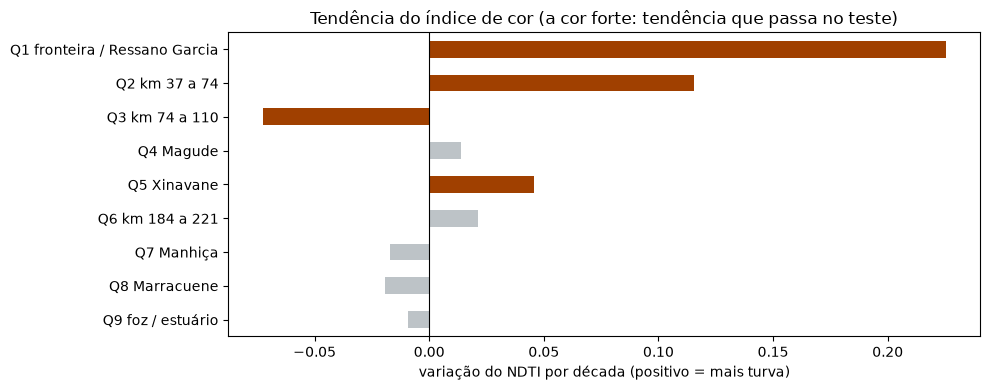

In [5]:
trend = Q.trends(data)
trend.round(5).to_csv(REPORTS / "36_tendencias.csv", index=False)
full = trend[trend["periodo"] == "registo completo"]
pivot = full.pivot(index="nome", columns="parametro", values="leitura").reindex([names[t] for t in sorted(data["troco"].unique())]).fillna("sem tendência")
display(pivot)
shown = full[full["parametro"] == "ndti"].set_index("nome").reindex(pivot.index)
colours = np.where(shown["leitura"].fillna("").str.startswith("confirmada") | shown["leitura"].fillna("").str.startswith("um só"), "#a04000", "#bdc3c7")
ax = shown["inclinacao_por_decada"].plot.barh(figsize=(10, 4), color=colours); ax.invert_yaxis(); ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("variação do NDTI por década (positivo = mais turva)"); ax.set_ylabel("")
ax.set_title("Tendência do índice de cor (a cor forte: tendência que passa no teste)")
plt.tight_layout(); plt.savefig(REPORTS / "36_tendencias.png", dpi=110)
trend[trend["tendencia"].isin(["sobe", "desce"])][["nome", "parametro", "periodo", "tendencia", "inclinacao_por_decada", "p", "n", "leitura"]]

**Como ler**

- `tendencia`: sobe, desce ou sem tendência (ao nível de 5 %).
- `leitura`: "confirmada" quando a era Landsat 8/9 mostra o mesmo; "não confirmada"
  quando só aparece no registo completo; "um só satélite" nos troços estreitos,
  onde a série é só do Sentinel-2 e por isso mais curta (desde 2017).

**O que se pode dizer.** Só as tendências confirmadas. As dos troços estreitos
valem para nove anos (2017 a 2026), não para vinte. Esses nove anos começam em
anos de seca (2017 a 2019) e acabam em anos de muita água e numa grande cheia
(2026). É o que se espera ver: mais caudal, água mais turva e menos plantas
paradas sobre a água. Devem ser lidas como "os últimos anos foram mais turvos do
que os primeiros", não como uma mudança permanente do rio. Nos troços com
fiabilidade reduzida, nem isso.

**O que o teste não corrige.** Meses seguidos parecem-se uns com os outros, o que
torna o teste um pouco otimista. E a temperatura vem de duas bandas térmicas
diferentes antes e depois de 2013.

## O que este notebook entrega

- `36_normais_por_troco_e_mes.csv`: o normal usado pela plataforma para dizer
  "normal / elevada / muito elevada".
- `36_anomalias.csv` e `36_meses_invulgares.csv`: os meses a olhar.
- `36_tendencias.csv`: tendências com a sua leitura.